### 선형 회귀 실습 문제

# Tips Dataset
: 레스토랑의 총 식사 금액을 이용해 손님이 지불할 팁 금액을 예측하는 선형 회귀 모델 구현.

#### Step1. 데이터 불러오기 및 전처리

**사용 데이터: Tips Dataset**

- 데이터: 244개
- 입력 특징: 1개 (총 식사 금액 (`total_bill`))
- 정답: 팁 금액(`tip`)

| 열 이름 | 의미 | 설명 |
|:---:|:---:|:---|
| `total_bill` | 총 식사 금액 | 식사에 청구된 총 금액 |
| `tip` | 팁 금액 | 종업원에게 지불한 팁 |
| `sex` | 성별 | 계산한 손님의 성별 |
| `smoker` | 흡연 여부 | 흡연자 여부 |
| `day` | 요일 | 식사한 요일 |
| `time` | 식사 시간 | Lunch 또는 Dinner |
| `size` | 인원수 | 테이블의 손님 수 |

**실습 조건**
- 입력값(X): `total_bill`
- 정답(y): `tip`
- 결측치가 있는지 확인하고, 필요한 경우 처리한다.
- 학습 데이터와 테스트 데이터를 8:2 비율로 분리한다.
- 입력값은 학습 데이터의 평균과 표준편차를 이용해 표준화한다.
- `total_bill`과 `tip`의 관계를 산점도로 먼저 확인한다.

In [1]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
import seaborn as sns
import pandas as pd 
import torch
import matplotlib.pyplot as plt 
from torch.utils.data import TensorDataset, DataLoader
from torch import nn, optim
import numpy as np 

# 난수 시드 고정 
torch.manual_seed(42)

In [ ]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/tips.csv"
df = pd.read_csv(url)

# 이번 실습에 필요한 두 열만 사용
df = df[["total_bill", "tip"]].dropna().copy()
x = torch.tensor(df[["total_bill"]].values, dtype = torch.float32)
y = torch.tensor(df[['tip']].values, dtype = torch.float32)

print('입력값 :', x)
print('입력 shape :', x.shape)
print('정답 :',y)
print('정답 shape :', y.shape)

정답 : tensor([[ 1.0100],
        [ 1.6600],
        [ 3.5000],
        [ 3.3100],
        [ 3.6100],
        [ 4.7100],
        [ 2.0000],
        [ 3.1200],
        [ 1.9600],
        [ 3.2300],
        [ 1.7100],
        [ 5.0000],
        [ 1.5700],
        [ 3.0000],
        [ 3.0200],
        [ 3.9200],
        [ 1.6700],
        [ 3.7100],
        [ 3.5000],
        [ 3.3500],
        [ 4.0800],
        [ 2.7500],
        [ 2.2300],
        [ 7.5800],
        [ 3.1800],
        [ 2.3400],
        [ 2.0000],
        [ 2.0000],
        [ 4.3000],
        [ 3.0000],
        [ 1.4500],
        [ 2.5000],
        [ 3.0000],
        [ 2.4500],
        [ 3.2700],
        [ 3.6000],
        [ 2.0000],
        [ 3.0700],
        [ 2.3100],
        [ 5.0000],
        [ 2.2400],
        [ 2.5400],
        [ 3.0600],
        [ 1.3200],
        [ 5.6000],
        [ 3.0000],
        [ 5.0000],
        [ 6.0000],
        [ 2.0500],
        [ 3.0000],
        [ 2.5000],
        [ 2.6000],
       

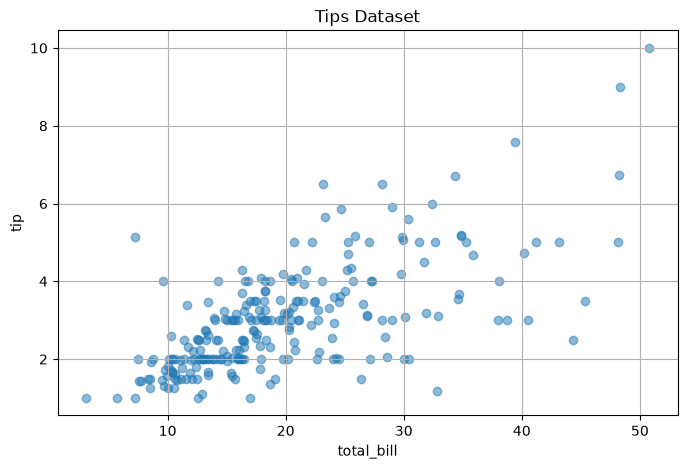

In [ ]:
plt.figure(figsize = (8,5)) # 가로 8인치, 세로 5인치 

plt.scatter(x, y, alpha = 0.5) # 투명도 50% 

plt.xlabel('total_bill')
plt.ylabel('tip')
plt.title('Tips Dataset')
plt.grid(True)

244


In [ ]:
indices = torch.randperm(len(x)) # 0부터 시작해서 x까지 무작위로 섞는 함수
train_size = int(len(x)*0.8) ## 195, len(x) = 244

train_indices = indices[:train_size]
test_indices = indices[train_size:]

x_train = x[train_indices] ## 트레이닝 입력값
x_test = x[test_indices] ## 2차원으로 텐서 변경 후 행렬 바꾸기 
y_train = y[train_indices]
y_test = y[test_indices]

mean = x_train.mean(dim = 0)
std = x_train.std(dim=0).clamp(min = 1e-8)

# 값을 표준화 시키기
x_train_scaled = (x_train - mean) / std
x_test_scaled = (x_test - mean) / std

print('x_train :', x_train_scaled.shape)
print('y_train :', y_train.shape)
print('x_test :', x_test_scaled.shape)
print('y_test :', y_test.shape)

x_train : torch.Size([195, 1])
y_train : torch.Size([195, 1])
x_test : torch.Size([49, 1])
y_test : torch.Size([49, 1])


In [ ]:
## DataLoader 생성
BATCH_SIZE = 32 # 한번의 학습단계에서 사용하는 데이터의 개수 

train_DS = TensorDataset(x_train_scaled, y_train) ## 연습 데이터 x,y 좌표 합치기
test_DS = TensorDataset(x_test_scaled, y_test) # 테스트 데이터 x,y 좌표 합치기

train_DL = DataLoader(train_DS, batch_size = BATCH_SIZE, shuffle = True) # 배치사이즈 만큼 데이터를 나누기
test_DL = DataLoader(test_DS, batch_size = BATCH_SIZE, shuffle = False)

N = len(train_DL.dataset)
print('학습데이터 개수 : ',N)

학습데이터 개수 :  195


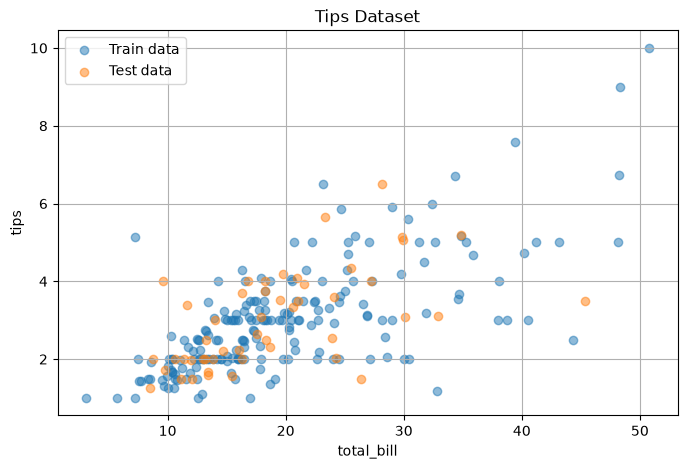

In [21]:
# 그래프로 보기 
plt.figure(figsize = (8,5))

plt.scatter(x_train, y_train, alpha = 0.5, label = 'Train data')
plt.scatter(x_test, y_test, alpha = 0.5, label = 'Test data')

plt.xlabel('total_bill')
plt.ylabel('tips')
plt.title('Tips Dataset')
plt.legend()
plt.grid(True)

#### Step2. 모델 만들기

- 입력 노드: 1개 (`total_bill`)
- 출력 노드: 1개 (`tip`)
- 활성화 함수: 사용하지 않음
- 모델: `nn.Linear`

In [11]:
model = nn.Linear(1,1)

# 임의의 값으로 데이터 5개 출력 확인
b = model(torch.randn(5,1))

print('출력 shape :', b.shape)
print(b)

출력 shape : torch.Size([5, 1])
tensor([[-0.3440],
        [ 0.4508],
        [ 0.4814],
        [-0.9027],
        [ 1.1935]], grad_fn=<AddmmBackward0>)


#### STEP 3. 모델 학습시키기

- Optimizer: SGD
- Loss function: MSELoss
- 학습률(LR): 0.01부터 시작
- Epoch: 200
- Batch size: 32

In [27]:
LR = 1e-2
EPOCH = 200

optimizer = optim.SGD(model.parameters(), lr = LR)
criterion = nn.MSELoss() ## 손실함수를 계산하여 나중에 가중치를 변경하여 오차를 줄이는 방향으로 계산 

loss_history = []

model.train() # 학습모드 전환
for ep in range(EPOCH) : 
    rloss = 0 

    for x_batch, y_batch in train_DL : 

        # inference 
        y_hat = model(x_batch)

        # loss 
        loss = criterion(y_hat, y_batch)

        # update 
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        rloss += loss.item()*x_batch.shape[0]

    loss_e = rloss / N
    loss_history.append(loss_e)

    if ep % 12 == 0 : 
        print(f'Epoch : {ep+1}, train loss : {loss_e : .4f}')
        print('-'*20)

Epoch : 1, train loss :  1.0431
--------------------
Epoch : 13, train loss :  1.0461
--------------------
Epoch : 25, train loss :  1.0429
--------------------
Epoch : 37, train loss :  1.0435
--------------------
Epoch : 49, train loss :  1.0433
--------------------
Epoch : 61, train loss :  1.0442
--------------------
Epoch : 73, train loss :  1.0419
--------------------
Epoch : 85, train loss :  1.0425
--------------------
Epoch : 97, train loss :  1.0427
--------------------
Epoch : 109, train loss :  1.0442
--------------------
Epoch : 121, train loss :  1.0455
--------------------
Epoch : 133, train loss :  1.0420
--------------------
Epoch : 145, train loss :  1.0421
--------------------
Epoch : 157, train loss :  1.0431
--------------------
Epoch : 169, train loss :  1.0416
--------------------
Epoch : 181, train loss :  1.0438
--------------------
Epoch : 193, train loss :  1.0456
--------------------


<function matplotlib.pyplot.grid(visible: 'bool | None' = None, which: "Literal['major', 'minor', 'both']" = 'major', axis: "Literal['both', 'x', 'y']" = 'both', **kwargs) -> 'None'>

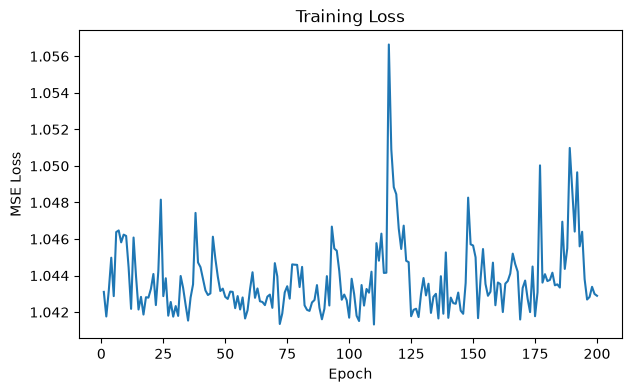

In [28]:
## loss 그래프 그리기 
plt.figure(figsize = (7,4))
plt.plot(range(1, EPOCH+1), loss_history)
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('Training Loss')
plt.grid

#### Step4. 모델 테스트하기


In [29]:
model.eval()
with torch.no_grad() : 
    y_pred = model(x_test_scaled)

test_loss = criterion(y_pred, y_test).item()
test_mean = torch.mean(torch.abs(y_pred - y_test)).item()
test_rmean = np.sqrt(test_loss)

print(f'Test MSE : {test_loss:.3f}')
print(f'Test MAE : {test_mean:.3f} MPG')
print(f'Test RMSE : {test_rmean:.3f} MPG')

Test MSE : 1.025
Test MAE : 0.792 MPG
Test RMSE : 1.012 MPG


#### Step5. 테스트 결과 시각화

**문제**
- 첫 번째 그래프: 테스트 데이터의 실제 산점도와 모델의 예측 회귀선을 함께 표시.
- 두 번째 그래프: 실제 팁 금액을 x축, 예측 팁 금액을 y축으로 하는 산점도를 작성.
- 두 번째 그래프에 완벽한 예측을 나타내는 기준선(y=x)을 추가.
- 그래프의 축 이름과 제목을 적절히 표시.

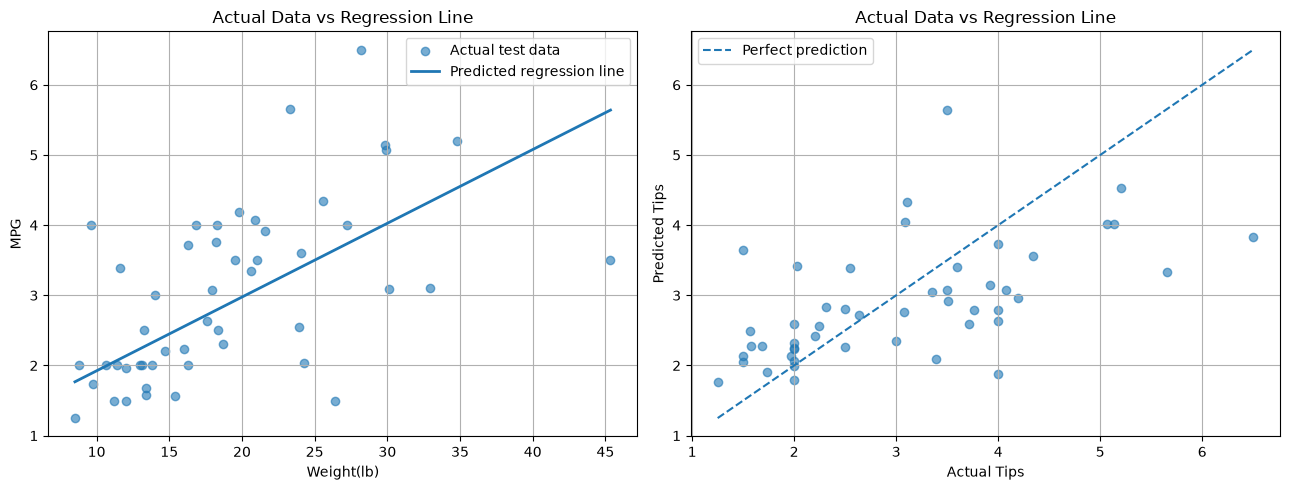

In [34]:
model.eval()
with torch.no_grad() : 
    y_pred = model(x_test_scaled)

# 무게를 기준으로 정렬을 하여 회귀선 표시 
# argsort : 정렬된 순서에 해당하는 인덱스 반환하는 함수 
sort_idx = torch.argsort(x_test.squeeze())
x_test_sorted = x_test[sort_idx]
x_test_scaled_sorted = x_test_scaled[sort_idx]
y_test_sorted = y_test[sort_idx]

with torch.no_grad() : 
    y_pred_sorted = model(x_test_scaled_sorted)

fig, axes = plt.subplots(1,2,figsize = (13,5))

# 실제 테스트 데이터와 예측 회귀선 
axes[0].scatter(x_test.numpy(), y_test.numpy(), alpha = 0.6, label = 'Actual test data')

axes[0].plot(x_test_sorted.numpy(), y_pred_sorted.numpy(), linewidth = 2, label = 'Predicted regression line')
axes[0].set_xlabel('Weight(lb)')
axes[0].set_ylabel('MPG')
axes[0].set_title('Actual Data vs Regression Line')
axes[0].legend()
axes[0].grid(True)

# 테스트의 실제값과 예측값 비교 
axes[1].scatter(y_test.numpy(), y_pred.numpy(), alpha = 0.6)
min_val = min(y_test.min().item(), y_pred.min().item())
max_val = max(y_test.max().item(), y_pred.max().item())
axes[1].plot([min_val, max_val], [min_val, max_val], linestyle = '--', label = 'Perfect prediction')
axes[1].set_xlabel('Actual Tips')
axes[1].set_ylabel('Predicted Tips')
axes[1].set_title('Actual Data vs Regression Line')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()









#### STEP 6. 파라미터 개수 확인